# 🦷 Dentura AI — Oral Pathology Deep Learning & Interpretability Pipeline

Oral disease classification research and model development using EfficientNetB0 transfer learning, custom 4-block Conv2D, ResNet50 baselines, and Grad-CAM interpretability across 6 distinct oral pathologies.

## 1. Setup & Imports 📦
Setting up the environment and importing required libraries.

In [ ]:
!pip install split-folders
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shutil
import splitfolders 
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import tensorflow as tf
from tensorflow import keras 
from tensorflow.keras import losses
from tensorflow.keras import callbacks
from tensorflow.keras import layers
from tensorflow.keras import optimizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam , Adamax
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.layers import Conv2D, MaxPooling2D , GlobalAveragePooling2D,Dropout,BatchNormalization,Input,Flatten,Dense
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as effnet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input

In [7]:
old_final = '/kaggle/working/managed_oral_data_split'
if os.path.exists(old_final):
    shutil.rmtree(old_final)
    print("Removed old split folder")
else:
    print("Nothing to remove")
old_staging = '/kaggle/working/managed_oral_data_raw'
if os.path.exists(old_staging):
    shutil.rmtree(old_staging)
    print("Removed old staging folder")

Removed old split folder
Removed old staging folder


In [8]:
base = '/kaggle/input/datasets/salmansajid05/oral-diseases'
staging = '/kaggle/working/managed_oral_data_raw'   # cleaned, unsplit images per class
final   = '/kaggle/working/managed_oral_data_split' # final train/val/test split
# exact paths to the ORIGINAL (non-augmented) image folders for each class
class_paths = {
    'Calculus':            os.path.join(base, 'Calculus', 'Calculus'),
    'Gingivitis':          os.path.join(base, 'Gingivitis', 'Gingivitis'),
    'Hypodontia':          os.path.join(base, 'hypodontia', 'hypodontia'),
    'Caries':              os.path.join(base, 'Data caries', 'Data caries', 'caries orignal data set', 'done'),
    'Mouth_Ulcer':         os.path.join(base, 'Mouth Ulcer', 'Mouth Ulcer', 'ulcer original dataset', 'ulcer original dataset'),
    'Tooth_Discoloration': os.path.join(base, 'Tooth Discoloration', 'Tooth Discoloration ', 'tooth discoloration original dataset', 'tooth discoloration original dataset'),
}

# 1. Copy into a clean staging folder: staging/<class_name>/<images>
os.makedirs(staging, exist_ok=True)
for cls, path in class_paths.items():
    dest = os.path.join(staging, cls)
    os.makedirs(dest, exist_ok=True)
    files = os.listdir(path)
    for f in files:
        src_file = os.path.join(path, f)
        if os.path.isfile(src_file):
            shutil.copy2(src_file, os.path.join(dest, f))
    print(f"{cls}: copied {len(files)} files")

# 2. Split into train/test (80/20), stratified per class automatically
splitfolders.ratio(
    input=staging,
    output=final,
    seed=42,
    ratio=(0.8, 0.2)   
)
val_dir = os.path.join(final, 'val')
test_dir = os.path.join(final, 'test')

if os.path.exists(val_dir):
    os.rename(val_dir, test_dir)


Calculus: copied 1296 files
Gingivitis: copied 2349 files
Hypodontia: copied 1251 files
Caries: copied 219 files
Mouth_Ulcer: copied 265 files
Tooth_Discoloration: copied 183 files


Copying files: 5563 files [00:00, 7058.05 files/s]


In [9]:
TrainPath = os.path.join(final, 'train')
TestPath  = os.path.join(final, 'test')

batchsize    = 32
image_height = 224
image_width = 224
num_classes  = 6
epochs       = 200

In [10]:
for split in ['train', 'test']:
    print(f"\n{split}:")
    split_dir = os.path.join(final, split)
    for cls in os.listdir(split_dir):
        n = len(os.listdir(os.path.join(split_dir, cls)))
        print(f"  {cls}: {n}")


train:
  Calculus: 1036
  Caries: 175
  Gingivitis: 1879
  Mouth_Ulcer: 212
  Hypodontia: 1000
  Tooth_Discoloration: 146

test:
  Calculus: 260
  Caries: 44
  Gingivitis: 470
  Mouth_Ulcer: 53
  Hypodontia: 251
  Tooth_Discoloration: 37


---
## 2. Dataset Setup & Preprocessing 🗂️
Loading the dataset, verifying paths, and preparing the images for the model.

In [11]:
train_ds = image_dataset_from_directory(
    TrainPath,
    labels='inferred',
    label_mode='categorical',      
    validation_split=0.2,
    batch_size=batchsize,
    image_size=(image_width, image_height),
    subset='training',
    seed=0
)

validation_ds = image_dataset_from_directory(
    TrainPath,
    labels='inferred',
    label_mode='categorical',
    validation_split=0.2,
    batch_size=batchsize,
    image_size=(image_width, image_height),
    subset='validation',
    seed=0
)

test_ds = image_dataset_from_directory(
    TestPath,
    labels='inferred',
    label_mode='categorical',
    batch_size=batchsize,
    image_size=(image_width, image_height),
    shuffle=False
)

Found 4448 files belonging to 6 classes.
Using 3559 files for training.


I0000 00:00:1783777488.976026      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783777488.978988      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 4448 files belonging to 6 classes.
Using 889 files for validation.
Found 1115 files belonging to 6 classes.


In [14]:
img_augmentation = Sequential(
    [
        layers.RandomRotation(factor=0.15),
        layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
        layers.RandomFlip(mode="horizontal"),
        layers.RandomZoom(height_factor=0.1, width_factor=0.1),
        layers.RandomContrast(factor=0.1),
    ],
    name='img_augmentation'
)

In [16]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [12]:
train_ds

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 6), dtype=tf.float32, name=None))>

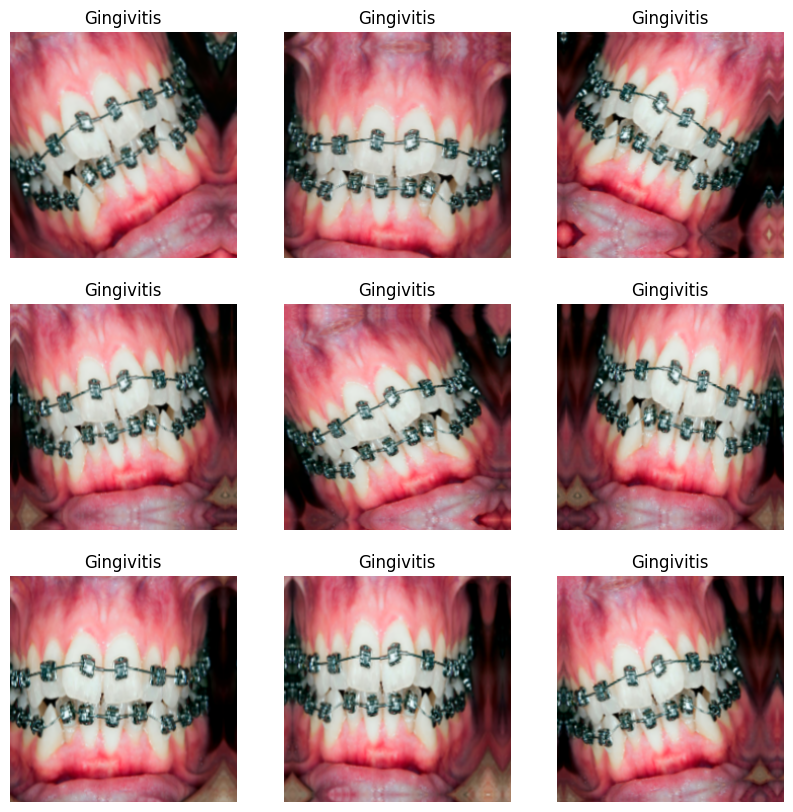

In [15]:
plt.figure(figsize=(10,10))
for image, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        aug_img = img_augmentation(tf.expand_dims(image[0], axis=0), training=True)  # (1,224,224,3)
        aug_img = tf.clip_by_value(aug_img, 0, 255)
        plt.imshow(aug_img[0].numpy().astype('uint8'))
        label_idx = tf.argmax(labels[0]).numpy()   # convert one-hot -> class index
        plt.title(class_names[label_idx])
        plt.axis('off')
plt.show()

---
## 3. Model Training 🚀
Initializing the deep learning model and starting the training process. This is where the model learns the patterns from the dataset.

In [55]:
def build_cnn(input_shape=(224,224,3), num_classes=6):
    model = Sequential([
        Input(shape=input_shape),
        img_augmentation,
        layers.Rescaling(1./255),

        Conv2D(32, (3,3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2,2)),

        Conv2D(64, (3,3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2,2)),

        Conv2D(128, (3,3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2,2)),

        Conv2D(256, (3,3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2,2)),

        GlobalAveragePooling2D(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])

    optimizer = optimizers.Adam(learning_rate=1e-3)
    loss = losses.CategoricalCrossentropy()
    model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])
    model.summary()
    return model

In [56]:
cnn = build_cnn()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ img_augmentation (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_11 (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 457,670 (1.75 MB)

 Trainable params: 456,710 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

In [59]:


model = build_cnn(input_shape=(224,224,3), num_classes=6)
history_cnn = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=epochs,
    callbacks=[lr_callback, stop_callback, model_ckpt],
    verbose=1
)

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ img_augmentation (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_13 (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_35          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_37          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 457,670 (1.75 MB)

 Trainable params: 456,710 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/200
111/112 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.4494 - loss: 1.4516

... (7 outputs left out)

112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 133ms/step - accuracy: 0.7890 - loss: 0.5324 - val_accuracy: 0.7233 - val_loss: 0.6678 - learning_rate: 2.0000e-04
Epoch 19/200
111/112 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.7934 - loss: 0.5008

112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.7952 - loss: 0.4909 - val_accuracy: 0.7660 - val_loss: 0.6001 - learning_rate: 2.0000e-04
Epoch 20/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 131ms/step - accuracy: 0.8039 - loss: 0.4914 - val_accuracy: 0.7660 - val_loss: 0.5947 - learning_rate: 2.0000e-04
Epoch 21/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8044 - loss: 0.4763 - val_accuracy: 0.7660 - val_loss: 0.5983 - learning_rate: 2.0000e-04
Epoch 22/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8098 - loss: 0.4653 - val_accuracy: 0.7537 - val_loss: 0.6432 - learning_rate: 2.0000e-04
Epoch 23/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8210 - loss: 0.4564 - val_accuracy: 0.7525 - val_loss: 0.6496 - learning_rate: 2.0000e-04
Epoch 24/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8238 - loss: 0.4398 - val_accuracy: 0.7435 - val_loss: 0.6901 - learning_rate: 2.0000e-04
Epoch 25/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 1

112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 133ms/step - accuracy: 0.8261 - loss: 0.4214 - val_accuracy: 0.7739 - val_loss: 0.5900 - learning_rate: 4.0000e-05
Epoch 27/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8275 - loss: 0.4141 - val_accuracy: 0.7638 - val_loss: 0.5900 - learning_rate: 4.0000e-05
Epoch 28/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8235 - loss: 0.4105 - val_accuracy: 0.7649 - val_loss: 0.5920 - learning_rate: 4.0000e-05
Epoch 29/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8317 - loss: 0.4026 - val_accuracy: 0.7660 - val_loss: 0.5821 - learning_rate: 4.0000e-05
Epoch 30/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8339 - loss: 0.4067 - val_accuracy: 0.7705 - val_loss: 0.5818 - learning_rate: 4.0000e-05
Epoch 31/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8398 - loss: 0.3985 - val_accuracy: 0.7705 - val_loss: 0.5903 - learning_rate: 4.0000e-05
Epoch 32/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 1

112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8351 - loss: 0.3926 - val_accuracy: 0.7807 - val_loss: 0.5788 - learning_rate: 4.0000e-05
Epoch 34/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8362 - loss: 0.4017 - val_accuracy: 0.7660 - val_loss: 0.5874 - learning_rate: 4.0000e-05
Epoch 35/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8314 - loss: 0.3937 - val_accuracy: 0.7773 - val_loss: 0.5844 - learning_rate: 4.0000e-05
Epoch 36/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 131ms/step - accuracy: 0.8328 - loss: 0.4012 - val_accuracy: 0.7705 - val_loss: 0.5763 - learning_rate: 4.0000e-05
Epoch 37/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.8390 - loss: 0.3883 - val_accuracy: 0.7717 - val_loss: 0.5839 - learning_rate: 4.0000e-05
Epoch 38/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 131ms/step - accuracy: 0.8348 - loss: 0.3929 - val_accuracy: 0.7705 - val_loss: 0.5651 - learning_rate: 8.0000e-06
Epoch 39/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 15s 1

In [64]:
model2 = build_model()   # actually creates and compiles the EfficientNetB0 model

history2 = model2.fit(
    train_ds,
    validation_data=validation_ds,
    callbacks=[lr_callback, stop_callback, model_ckpt2],
    epochs=epochs,
    verbose=1
)

Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_15      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ img_augmentation    │ (None, 224, 224,  │          0 │ input_layer_15[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_6 (Lambda)   │ (None, 224, 224,  │          0 │ img_augmentation… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_14        │ (None, 224, 224,  │          0 │ lambda_6[0][0]    │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_3     │ (None, 224, 224,  │          7 │ rescaling_14[0][… │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_15        │ (None, 224, 224,  │          0 │ normalization_3[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_15[0][… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc

 Total params: 4,062,377 (15.50 MB)

 Trainable params: 4,017,794 (15.33 MB)

 Non-trainable params: 44,583 (174.16 KB)

Epoch 1/200


... (9 outputs left out)

112/112 ━━━━━━━━━━━━━━━━━━━━ 40s 360ms/step - accuracy: 0.8862 - loss: 0.2438 - val_accuracy: 0.8414 - val_loss: 0.4077 - learning_rate: 2.0000e-04
Epoch 17/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 40s 353ms/step - accuracy: 0.8969 - loss: 0.2238 - val_accuracy: 0.8403 - val_loss: 0.4151 - learning_rate: 2.0000e-04
Epoch 18/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - accuracy: 0.9008 - loss: 0.2338

112/112 ━━━━━━━━━━━━━━━━━━━━ 40s 359ms/step - accuracy: 0.9031 - loss: 0.2162 - val_accuracy: 0.8436 - val_loss: 0.4306 - learning_rate: 2.0000e-04
Epoch 19/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 39s 353ms/step - accuracy: 0.9064 - loss: 0.2036 - val_accuracy: 0.8403 - val_loss: 0.4254 - learning_rate: 2.0000e-04
Epoch 20/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 40s 353ms/step - accuracy: 0.9045 - loss: 0.2042 - val_accuracy: 0.8369 - val_loss: 0.4428 - learning_rate: 2.0000e-04
Epoch 21/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 40s 353ms/step - accuracy: 0.9053 - loss: 0.1986 - val_accuracy: 0.8391 - val_loss: 0.4187 - learning_rate: 2.0000e-04
Epoch 22/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 40s 353ms/step - accuracy: 0.9121 - loss: 0.1868 - val_accuracy: 0.8425 - val_loss: 0.4239 - learning_rate: 4.0000e-05
Epoch 23/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - accuracy: 0.9117 - loss: 0.1904

112/112 ━━━━━━━━━━━━━━━━━━━━ 40s 359ms/step - accuracy: 0.9151 - loss: 0.1847 - val_accuracy: 0.8470 - val_loss: 0.4265 - learning_rate: 4.0000e-05
Epoch 24/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 40s 353ms/step - accuracy: 0.9137 - loss: 0.1888 - val_accuracy: 0.8448 - val_loss: 0.4282 - learning_rate: 4.0000e-05
Epoch 25/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 40s 353ms/step - accuracy: 0.9092 - loss: 0.1802 - val_accuracy: 0.8436 - val_loss: 0.4258 - learning_rate: 4.0000e-05
Epoch 26/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - accuracy: 0.9199 - loss: 0.1735

112/112 ━━━━━━━━━━━━━━━━━━━━ 40s 359ms/step - accuracy: 0.9160 - loss: 0.1754 - val_accuracy: 0.8493 - val_loss: 0.4289 - learning_rate: 4.0000e-05


In [ ]:
model_ckpt2 = callbacks.ModelCheckpoint(
    "best_pretrained_EfficientNetB0_model.h5",
    save_best_only=True,
    monitor="val_accuracy",
    mode="max"
)

def build_model():
    inputs = layers.Input(shape=(image_width, image_height, 3))
    x = img_augmentation(inputs)
    x = layers.Lambda(preprocess_input)(x)          # fix: EfficientNet-specific preprocessing
    model = EfficientNetB0(include_top=False, weights='imagenet', input_tensor=x)

    # Rebuild top
    x = layers.GlobalAveragePooling2D(name='avg_pool')(model.output)
    x = layers.BatchNormalization()(x)

    top_dropout_rate = 0.4
    x = layers.Dropout(top_dropout_rate, name='top_dropout')(x)
    output = layers.Dense(num_classes, activation='softmax', name="pred")(x)   # fix: softmax not sigmoid

    # compile
    model2 = tf.keras.Model(inputs, output, name='EfficientNetB0')
    optimizer = optimizers.Adam(learning_rate=1e-3)
    loss = losses.CategoricalCrossentropy()   # fix: matches your one-hot labels
    model2.compile(
        optimizer=optimizer, loss=loss, metrics=['accuracy']
    )
    model2.summary()
    return model2

In [58]:
lr_callback = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-7)
stop_callback = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
model_ckpt = callbacks.ModelCheckpoint("cnn_model.h5", save_best_only=True, monitor="val_accuracy", mode="max")

In [81]:
def build_resnet_model():
    inputs = layers.Input(shape=(image_width, image_height, 3))
    x = img_augmentation(inputs)
    x = layers.Lambda(resnet_preprocess)(x)
    model = ResNet50(include_top=False, weights='imagenet', input_tensor=x)

    # Rebuild top
    x = layers.GlobalAveragePooling2D(name='avg_pool')(model.output)
    x = layers.BatchNormalization()(x)

    top_dropout_rate = 0.4
    x = layers.Dropout(top_dropout_rate, name='top_dropout')(x)
    output = layers.Dense(num_classes, activation='softmax', name="pred")(x)

    model3 = tf.keras.Model(inputs, output, name='ResNet50')
    optimizer = optimizers.Adam(learning_rate=1e-3)
    loss = losses.CategoricalCrossentropy()
    model3.compile(
        optimizer=optimizer, loss=loss, metrics=['accuracy']
    )
    model3.summary()
    return model3

In [74]:
model_ckpt_resnet = callbacks.ModelCheckpoint("best_pretrained_ResNet50_model.h5",save_best_only=True,monitor="val_accuracy",mode="max")

In [82]:
model3 = build_resnet_model()

history_resnet = model3.fit(
    train_ds,
    validation_data=validation_ds,
    callbacks=[lr_callback, stop_callback, model_ckpt_resnet],
    epochs=epochs,
    verbose=1
)

Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_18      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ img_augmentation    │ (None, 224, 224,  │          0 │ input_layer_18[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_9 (Lambda)   │ (None, 224, 224,  │          0 │ img_augmentation… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ lambda_9[0][0]    │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r

 Total params: 23,608,198 (90.06 MB)

 Trainable params: 23,550,982 (89.84 MB)

 Non-trainable params: 57,216 (223.50 KB)

Epoch 1/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 555ms/step - accuracy: 0.4753 - loss: 1.9188

... (4 outputs left out)

112/112 ━━━━━━━━━━━━━━━━━━━━ 66s 586ms/step - accuracy: 0.6951 - loss: 0.8280 - val_accuracy: 0.7098 - val_loss: 0.7702 - learning_rate: 2.0000e-04
Epoch 7/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 0.7078 - loss: 0.7843

112/112 ━━━━━━━━━━━━━━━━━━━━ 66s 588ms/step - accuracy: 0.7176 - loss: 0.7607 - val_accuracy: 0.7267 - val_loss: 0.7605 - learning_rate: 2.0000e-04
Epoch 8/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 0.7202 - loss: 0.7459

112/112 ━━━━━━━━━━━━━━━━━━━━ 66s 588ms/step - accuracy: 0.7334 - loss: 0.7277 - val_accuracy: 0.7390 - val_loss: 0.8043 - learning_rate: 2.0000e-04
Epoch 9/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 0.7396 - loss: 0.7232

112/112 ━━━━━━━━━━━━━━━━━━━━ 66s 588ms/step - accuracy: 0.7452 - loss: 0.7156 - val_accuracy: 0.7424 - val_loss: 0.7421 - learning_rate: 2.0000e-04
Epoch 10/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 65s 577ms/step - accuracy: 0.7564 - loss: 0.6776 - val_accuracy: 0.7357 - val_loss: 0.7899 - learning_rate: 2.0000e-04


In [102]:
cnn.save("cnn_model.h5")
model2.save("best_pretrianed_EfficientNetB0_model.h5")

---
## 4. Evaluation & Results 📊
Analyzing how well the model performed using accuracy metrics, confusion matrices, and test predictions.

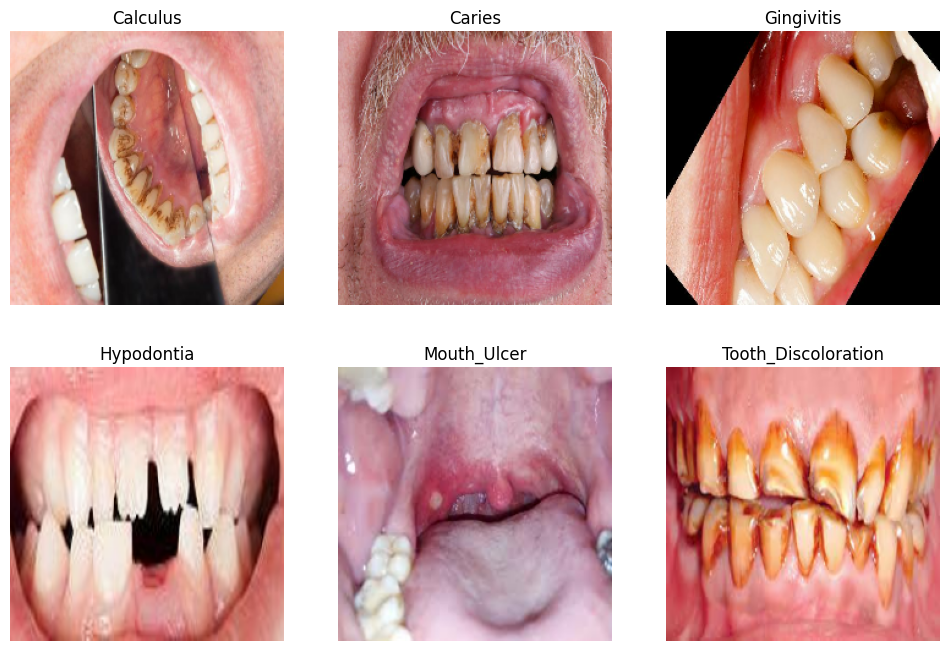

In [ ]:
class_names = train_ds.class_names
num_classes = len(class_names)

collected = {}

for images, labels in train_ds:
    label_indices = np.argmax(labels.numpy(), axis=1)
    for img, label_idx in zip(images.numpy(), label_indices):
        if label_idx not in collected:
            collected[label_idx] = img
    if len(collected) == num_classes:
        break 

plt.figure(figsize=(12, 8))
for i, cls_idx in enumerate(sorted(collected.keys())):
    ax = plt.subplot(2, 3, i + 1)
    plt.imshow(collected[cls_idx].astype("uint8"))
    plt.title(class_names[cls_idx])
    plt.axis("off")

plt.show()

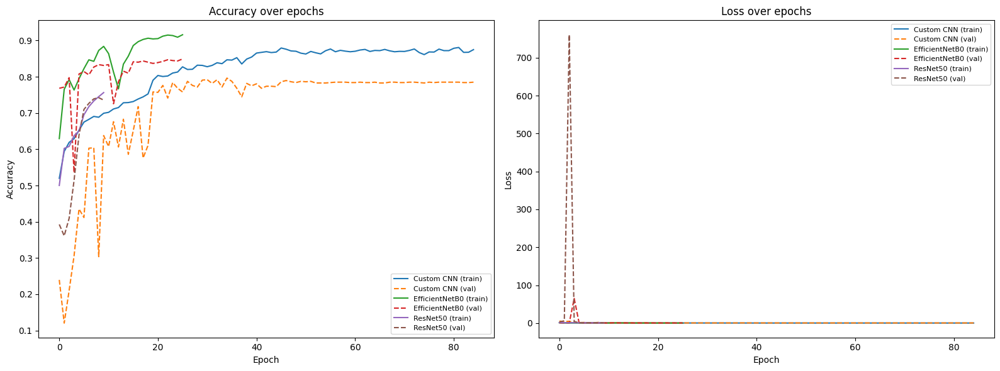

In [83]:
histories = {
    'Custom CNN': history,
    'EfficientNetB0': history2,
    'ResNet50': history_resnet
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, h in histories.items():
    axes[0].plot(h.history['accuracy'], label=f'{name} (train)')
    axes[0].plot(h.history['val_accuracy'], linestyle='--', label=f'{name} (val)')
    axes[1].plot(h.history['loss'], label=f'{name} (train)')
    axes[1].plot(h.history['val_loss'], linestyle='--', label=f'{name} (val)')

axes[0].set_title('Accuracy over epochs')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=8)

axes[1].set_title('Loss over epochs')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
model_paths = {
    'Custom CNN': ('cnn_model.h5', None),
    'EfficientNetB0': ('best_pretrained_EfficientNetB0_model.h5', {'preprocess_input': effnet_preprocess}),
    'ResNet50': ('best_pretrained_ResNet50_model.h5', {'preprocess_input': resnet_preprocess}),
}

# get true labels once (same order for all models since shuffle=False on test_ds)
y_true = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

all_results = {}
all_preds = {}

for name, (path, custom_obj) in model_paths.items():
    model = tf.keras.models.load_model(path, custom_objects=custom_obj)
    y_pred_probs = model.predict(test_ds)
    y_pred = np.argmax(y_pred_probs, axis=1)
    all_preds[name] = y_pred

    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    all_results[name] = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': report['weighted avg']['precision'],
        'Recall': report['weighted avg']['recall'],
        'F1-score': report['weighted avg']['f1-score']
    }

    print(f"\n{'='*60}\n{name} — Test Accuracy: {all_results[name]['Accuracy']:.4f}\n{'='*60}")
    print(classification_report(y_true, y_pred, target_names=class_names))

results_df = pd.DataFrame(all_results).T
print("\nSummary:\n", results_df)

35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step

Custom CNN — Test Accuracy: 0.7578
                     precision    recall  f1-score   support

           Calculus       0.60      0.70      0.64       260
             Caries       0.63      0.27      0.38        44
         Gingivitis       0.79      0.75      0.77       470
         Hypodontia       0.90      0.95      0.92       251
        Mouth_Ulcer       0.76      0.91      0.83        53
Tooth_Discoloration       0.75      0.32      0.45        37

           accuracy                           0.76      1115
          macro avg       0.74      0.65      0.67      1115
       weighted avg       0.76      0.76      0.75      1115



35/35 ━━━━━━━━━━━━━━━━━━━━ 7s 147ms/step

EfficientNetB0 — Test Accuracy: 0.8251
                     precision    recall  f1-score   support

           Calculus       0.66      0.74      0.70       260
             Caries       1.00      0.50      0.67        44
         Gingivitis       0.82      0.80      0.81       470
         Hypodontia       0.96      0.98      0.97       251
        Mouth_Ulcer       1.00      0.98      0.99        53
Tooth_Discoloration       0.82      0.84      0.83        37

           accuracy                           0.83      1115
          macro avg       0.88      0.81      0.83      1115
       weighted avg       0.83      0.83      0.83      1115



35/35 ━━━━━━━━━━━━━━━━━━━━ 9s 221ms/step

ResNet50 — Test Accuracy: 0.7318
                     precision    recall  f1-score   support

           Calculus       0.55      0.80      0.65       260
             Caries       0.61      0.25      0.35        44
         Gingivitis       0.81      0.66      0.72       470
         Hypodontia       0.88      0.93      0.90       251
        Mouth_Ulcer       0.79      0.87      0.83        53
Tooth_Discoloration       0.69      0.24      0.36        37

           accuracy                           0.73      1115
          macro avg       0.72      0.62      0.64      1115
       weighted avg       0.75      0.73      0.73      1115


Summary:
                 Accuracy  Precision    Recall  F1-score
Custom CNN      0.757848   0.760254  0.757848  0.751870
EfficientNetB0  0.825112   0.833062  0.825112  0.825164
ResNet50        0.731839   0.751322  0.731839  0.725911


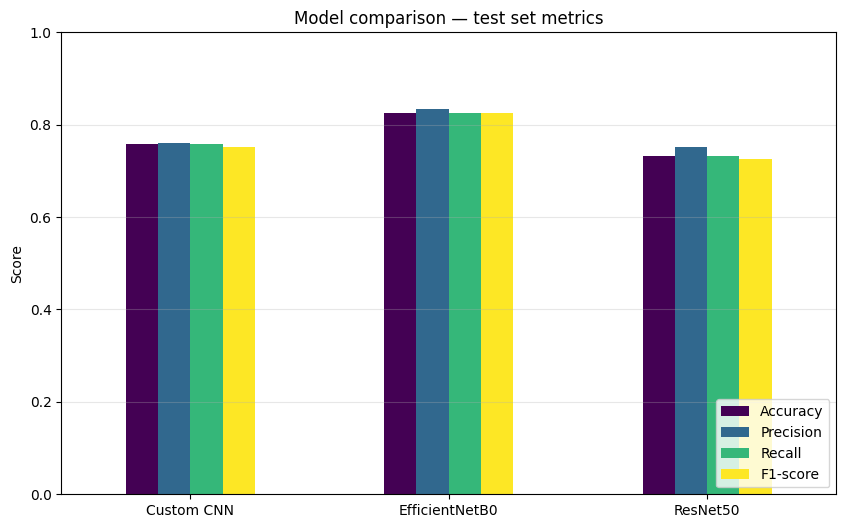

In [86]:
results_df.plot(kind='bar', figsize=(10,6), colormap='viridis')
plt.title('Model comparison — test set metrics')
plt.ylabel('Score')
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()

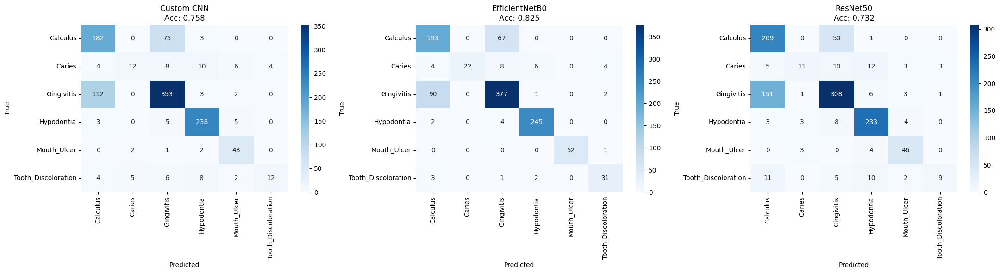

In [87]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for ax, (name, y_pred) in zip(axes, all_preds.items()):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f'{name}\nAcc: {all_results[name]["Accuracy"]:.3f}')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout()
plt.show()

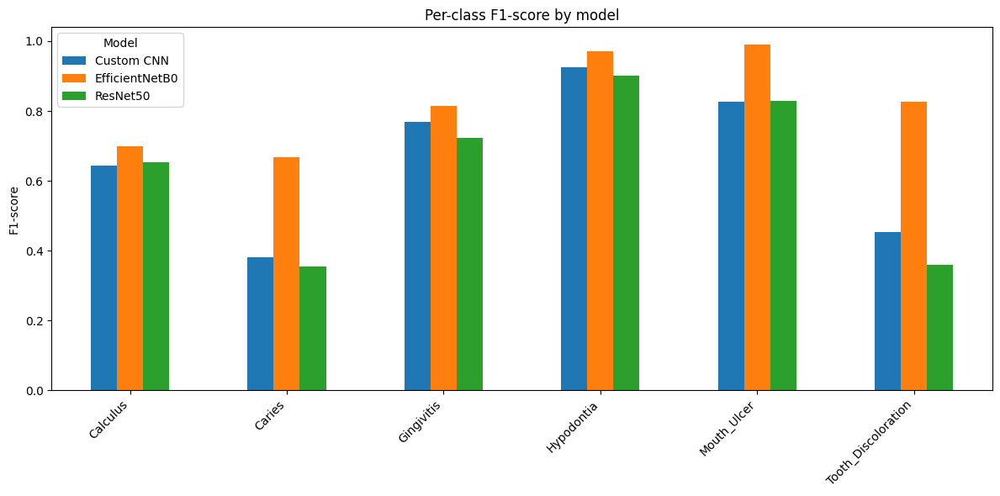

In [91]:
per_class_f1 = {}
for name, (path, custom_obj) in model_paths.items():
    y_pred = all_preds[name]
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    per_class_f1[name] = [report[c]['f1-score'] for c in class_names]

f1_df = pd.DataFrame(per_class_f1, index=class_names)
f1_df.plot(kind='bar', figsize=(12,6))
plt.title('Per-class F1-score by model')
plt.ylabel('F1-score')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Model')
plt.tight_layout()
plt.show()

In [97]:
def plot_predictions(model, model_name, num_images=9):
    plt.figure(figsize=(15, 15))
    plt.suptitle(model_name, fontsize=22)

    i = 0
    for images, labels in test_ds.take(3):
        preds = np.argmax(model.predict(images, verbose=0), axis=1)
        true_labels = np.argmax(labels.numpy(), axis=1)

        for j in range(len(images)):
            if i >= num_images:
                break
            ax = plt.subplot(3, 3, i + 1)
            plt.imshow(images[j].numpy().astype('uint8'))

            true_cls = class_names[true_labels[j]]
            pred_cls = class_names[preds[j]]
            color = 'green' if true_cls == pred_cls else 'red'

            plt.title(f"True: {true_cls}\nPred: {pred_cls}", color=color, fontsize=14)
            plt.axis('off')
            i += 1
        if i >= num_images:
            break

    plt.tight_layout()
    plt.show()

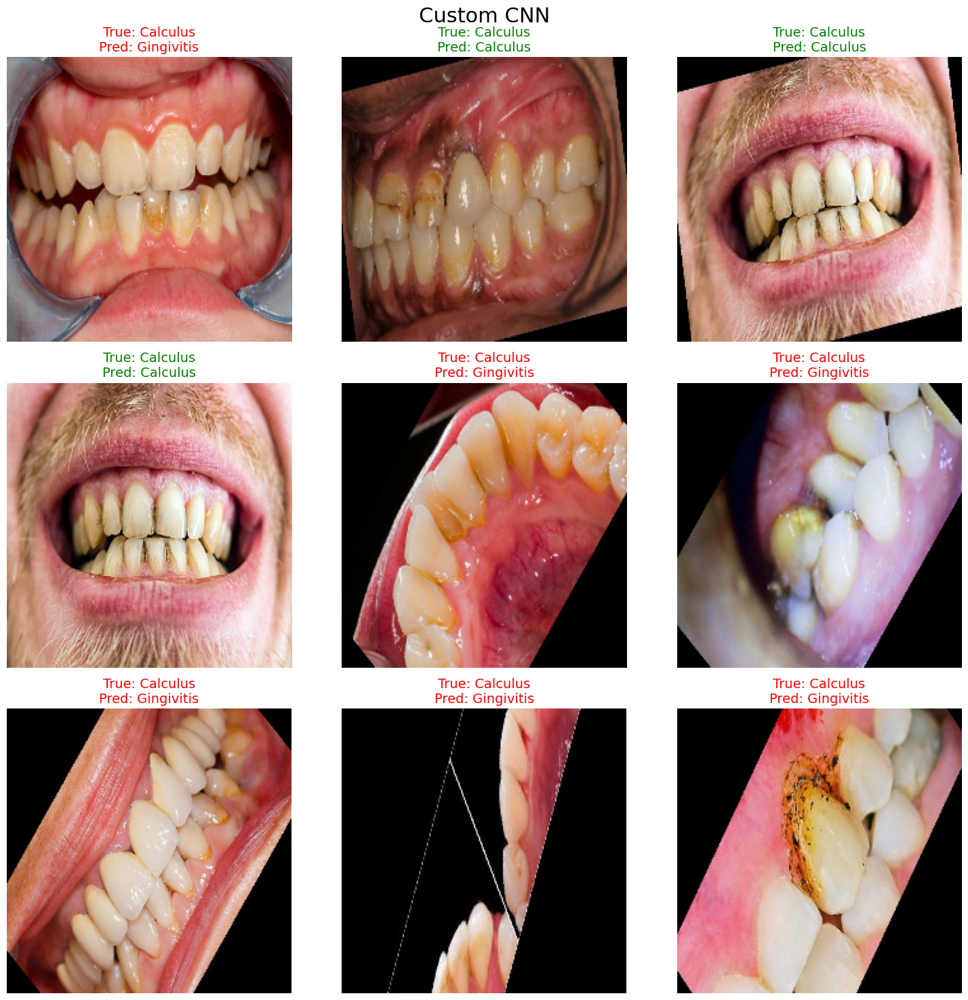

In [98]:
cnn_model = tf.keras.models.load_model("cnn_model.h5")
plot_predictions(cnn_model, "Custom CNN")

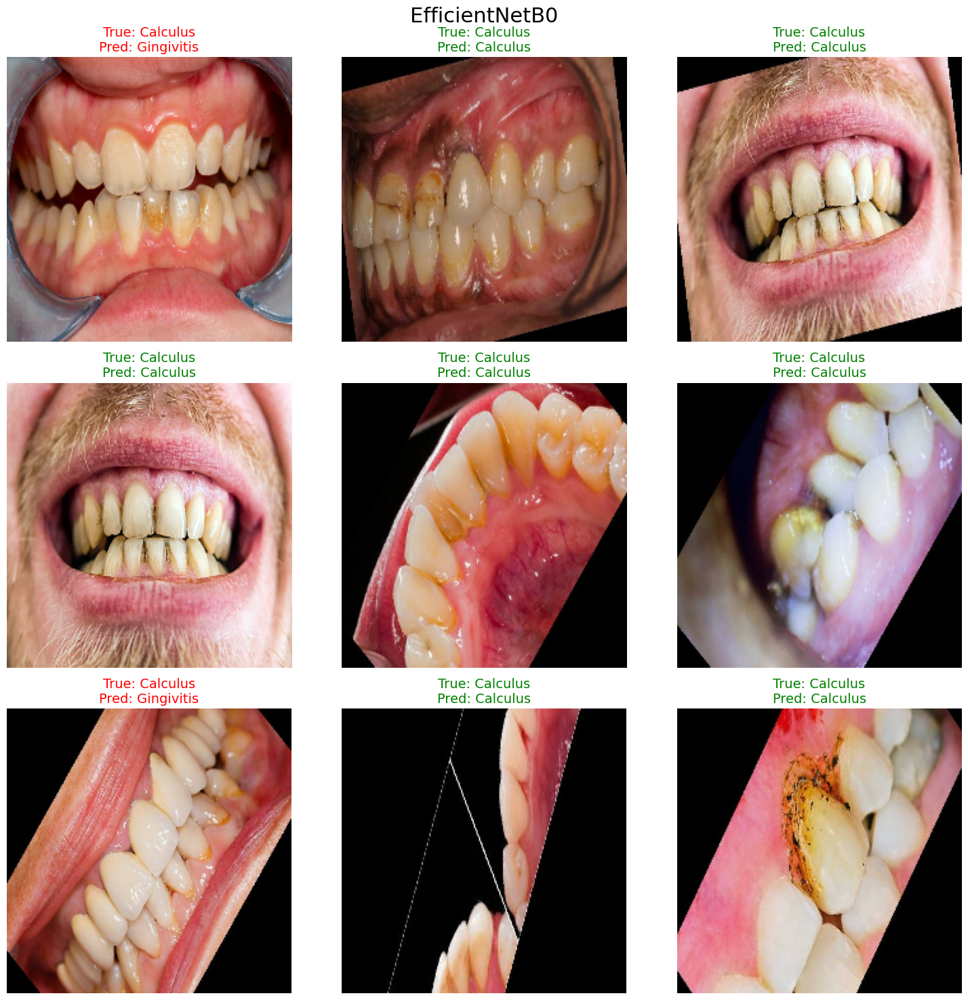

In [99]:
effnet_model = tf.keras.models.load_model("best_pretrained_EfficientNetB0_model.h5", custom_objects={'preprocess_input': effnet_preprocess})
plot_predictions(effnet_model, "EfficientNetB0")

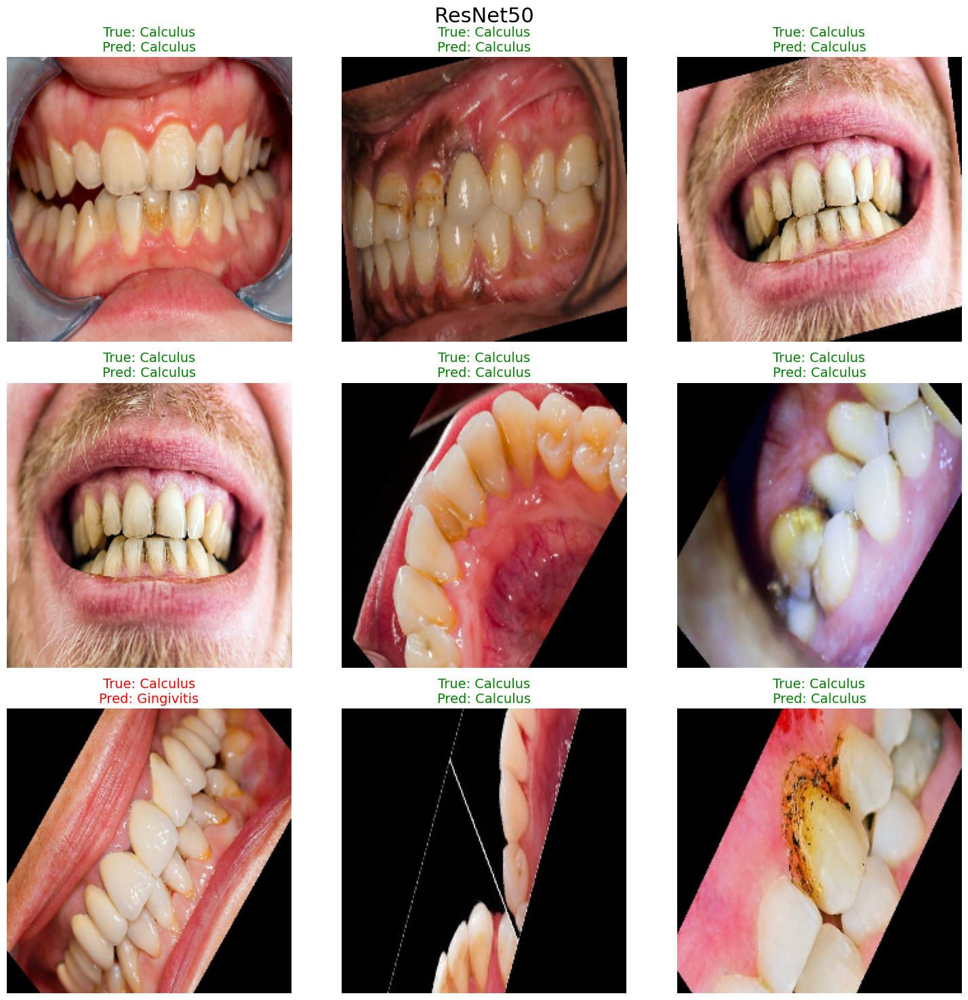

In [100]:
resnet_model = tf.keras.models.load_model("best_pretrained_ResNet50_model.h5", custom_objects={'preprocess_input': resnet_preprocess})
plot_predictions(resnet_model, "ResNet50")